<a href="https://colab.research.google.com/github/keyvanmahmoudi/Data_Science_Course/blob/main/sessions/Session09_statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۹: آمار برای علم داده

احتمال از مدل به داده می‌رسد («اگر سکه سالم باشد، چه می‌بینیم؟»). آمار برعکس است: از داده به مدل می‌رسد («با این داده، آیا سکه سالم است؟»).

### اهداف این جلسه

- آمار توصیفی: شاخص‌های مرکزی و پراکندگی و حساسیت آن‌ها به دادهٔ پرت
- جامعه و نمونه؛ **توزیع نمونه‌گیری** و **قضیهٔ حد مرکزی**
- خطای استاندارد و **بازهٔ اطمینان**
- **آزمون فرض**: فرض صفر، p-value و خطاهای نوع اول و دوم
- آزمون t، آزمون کای‌دو و آزمون جایگشتی
- همبستگی و اینکه چرا همبستگی به معنای علیت نیست
- تحلیل یک **آزمون A/B**
- اندازهٔ اثر و خطر **آزمون‌های چندگانه**

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(1405)
DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Data_Science_Course/main/data/"

tips = pd.read_csv(DATA_URL + "tips.csv")
tips["tip_pct"] = tips["tip"] / tips["total_bill"] * 100
tips.head()

,total_bill,tip,sex,smoker,day,time,size,tip_pct
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۱. آمار توصیفی

| مفهوم | شاخص | حساس به دادهٔ پرت؟ |
|---|---|---|
| مرکز | میانگین | بله |
| مرکز | میانه | خیر |
| پراکندگی | انحراف معیار | بله |
| پراکندگی | دامنهٔ میان‌چارکی (IQR) | خیر |
| شکل | چولگی (skewness) | — |

</div>

In [2]:
s = tips["tip_pct"]
summary = pd.Series({
    "mean": s.mean(), "median": s.median(),
    "std": s.std(), "IQR": s.quantile(0.75) - s.quantile(0.25),
    "min": s.min(), "max": s.max(), "skewness": s.skew(),
})
summary.round(2)

mean        16.08
median      15.48
std          6.11
IQR          6.23
min          3.56
max         71.03
skewness     3.35
dtype: float64

In [3]:
print("largest tip percentages:", s.nlargest(3).round(1).tolist())
trimmed = s[s < 40]
print(f"mean   with / without the outliers: {s.mean():.2f} / {trimmed.mean():.2f}")
print(f"median with / without the outliers: {s.median():.2f} / {trimmed.median():.2f}")
print(f"std    with / without the outliers: {s.std():.2f} / {trimmed.std():.2f}")

largest tip percentages: [71.0, 41.7, 32.6]
mean   with / without the outliers: 16.08 / 15.75
median with / without the outliers: 15.48 / 15.41
std    with / without the outliers: 6.11 / 4.72


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

یک مشتری ۷۱٪ انعام داده است! حذف فقط دو دادهٔ پرت، انحراف معیار را بیش از ۲۰٪ کم می‌کند، اما میانه تقریباً تغییری نمی‌کند. به همین دلیل گزارش‌هایی مثل «درآمد خانوار» معمولاً با **میانه** بیان می‌شوند.

> **انحراف معیار نمونه:** Pandas به‌طور پیش‌فرض در مخرج $n-1$ می‌گذارد (`ddof=1`) و NumPy $n$ (`ddof=0`). نسخهٔ $n-1$ برای تخمین انحراف معیار **جامعه** از روی نمونه بدون اریب است.

## ۲. جامعه، نمونه و توزیع نمونه‌گیری

- **جامعه**: همهٔ افراد مورد نظر (همهٔ مشتری‌های یک فروشگاه)
- **نمونه**: زیرمجموعه‌ای که واقعاً اندازه گرفته‌ایم
- **پارامتر**: عددی دربارهٔ جامعه (میانگین واقعی، $\mu$) که معمولاً نامعلوم است
- **آماره**: عددی که از نمونه حساب می‌کنیم ($\bar{x}$) تا پارامتر را تخمین بزنیم

هر نمونهٔ جدید، میانگین متفاوتی می‌دهد. توزیع این میانگین‌ها را **توزیع نمونه‌گیری** می‌گویند. بیایید یک «جامعه» با توزیع بسیار چوله (زمان انتظار، نمایی) بسازیم و ببینیم میانگین نمونه‌ها چه توزیعی دارد:

</div>

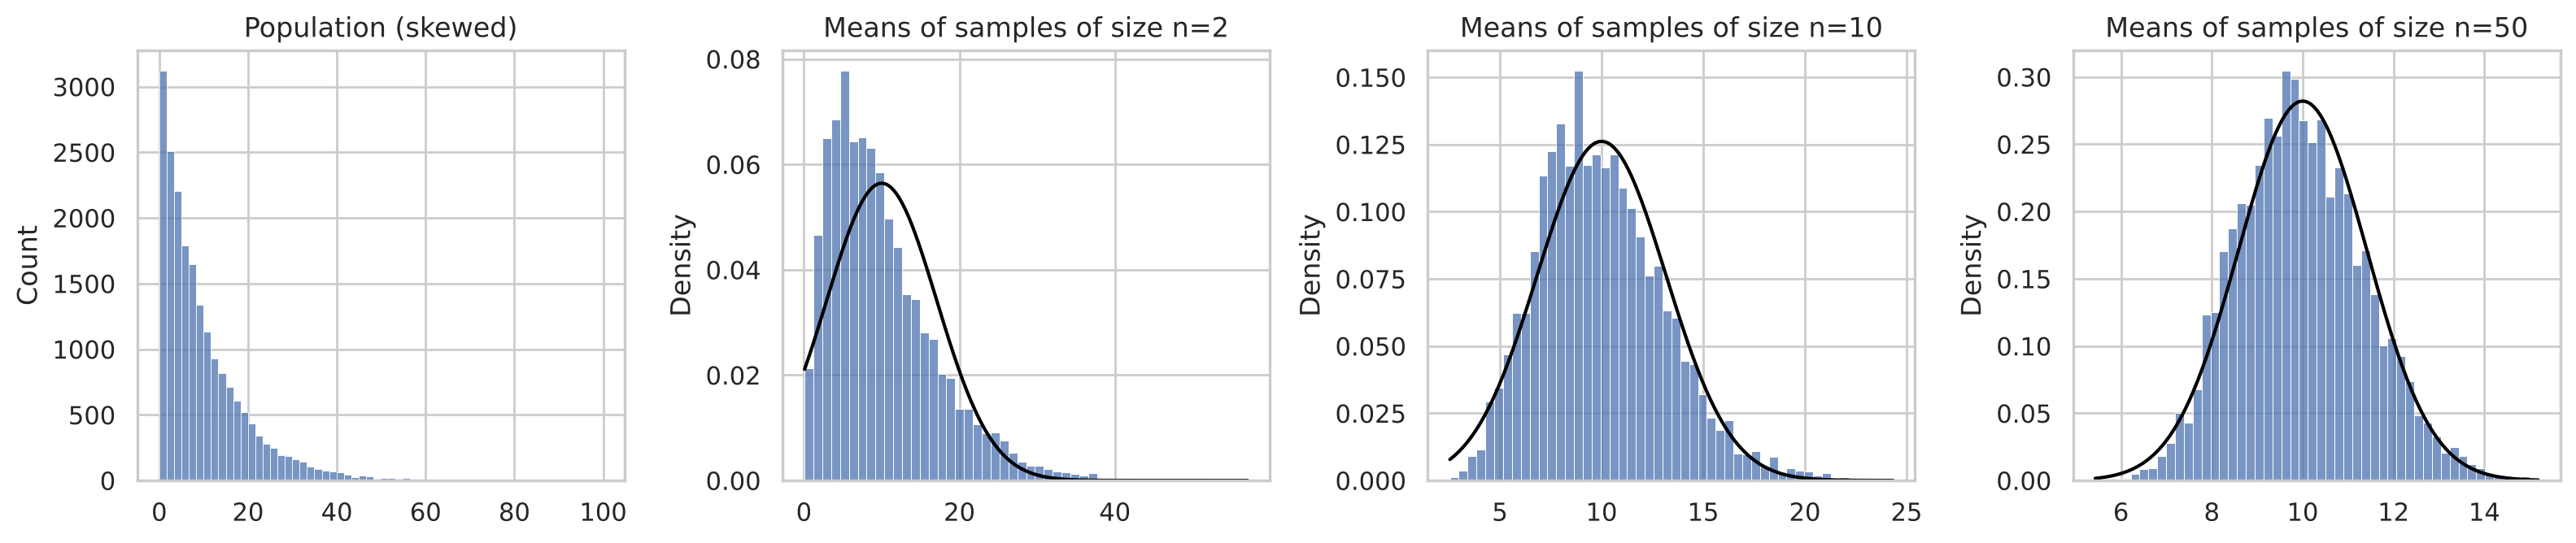

In [4]:
population = rng.exponential(scale=10, size=1_000_000)     # strongly right-skewed

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
sns.histplot(population[:20_000], bins=60, ax=axes[0])
axes[0].set_title("Population (skewed)")
for ax, n in zip(axes[1:], [2, 10, 50]):
    means = rng.choice(population, size=(5000, n)).mean(axis=1)
    sns.histplot(means, bins=50, stat="density", ax=ax)
    x = np.linspace(means.min(), means.max(), 200)
    ax.plot(x, stats.norm(10, 10 / np.sqrt(n)).pdf(x), color="black")
    ax.set_title(f"Means of samples of size n={n}")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### قضیهٔ حد مرکزی (CLT)

با بزرگ شدن اندازهٔ نمونه، توزیع میانگین نمونه‌ها **تقریباً نرمال** می‌شود، حتی اگر خود جامعه اصلاً نرمال نباشد. علاوه بر این:

$$\bar{X} \approx N\left(\mu,\; \frac{\sigma}{\sqrt{n}}\right)$$

عبارت $\sigma / \sqrt{n}$ را **خطای استاندارد (SE)** می‌گویند: میزان نوسان تخمین ما از یک نمونه به نمونهٔ دیگر. برای نصف کردن خطا، اندازهٔ نمونه باید **چهار برابر** شود.

این قضیه دلیل اصلی کارکرد بیشتر روش‌های آماری روی داده‌های واقعی و غیرنرمال است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۳. بازهٔ اطمینان

به‌جای یک عدد تنها («میانگین درصد انعام ۱۶٫۱ است»)، یک **بازه** گزارش می‌کنیم که عدم قطعیت را هم نشان دهد:

$$\bar{x} \pm t^* \times \frac{s}{\sqrt{n}}$$

که $t^*$ از توزیع t با $n-1$ درجهٔ آزادی می‌آید (برای ۹۵٪ و نمونهٔ بزرگ، تقریباً ۱٫۹۶).

</div>

In [5]:
n = len(s)
mean = s.mean()
se = s.std() / np.sqrt(n)
t_star = stats.t.ppf(0.975, df=n - 1)
print(f"n = {n}, mean = {mean:.2f}, SE = {se:.3f}, t* = {t_star:.3f}")
print(f"95% CI by formula : [{mean - t_star * se:.2f}, {mean + t_star * se:.2f}]")
print("95% CI by scipy   :", np.round(stats.t.interval(0.95, df=n - 1, loc=mean, scale=se), 2))

n = 244, mean = 16.08, SE = 0.391, t* = 1.970
95% CI by formula : [15.31, 16.85]
95% CI by scipy   : [15.31 16.85]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### معنای درست بازهٔ اطمینان ۹۵٪

**غلط:** «به احتمال ۹۵٪ میانگین واقعی در این بازه است.» (میانگین واقعی یک عدد ثابت است؛ یا در بازه هست یا نیست.)

**درست:** «اگر این روش را روی نمونه‌های زیادی تکرار کنیم، حدود ۹۵٪ بازه‌هایی که می‌سازیم میانگین واقعی را در بر می‌گیرند.»

شبیه‌سازی زیر دقیقاً همین را نشان می‌دهد: ۱۰۰ نمونه از جامعه‌ای با میانگین معلوم (۱۰).

</div>

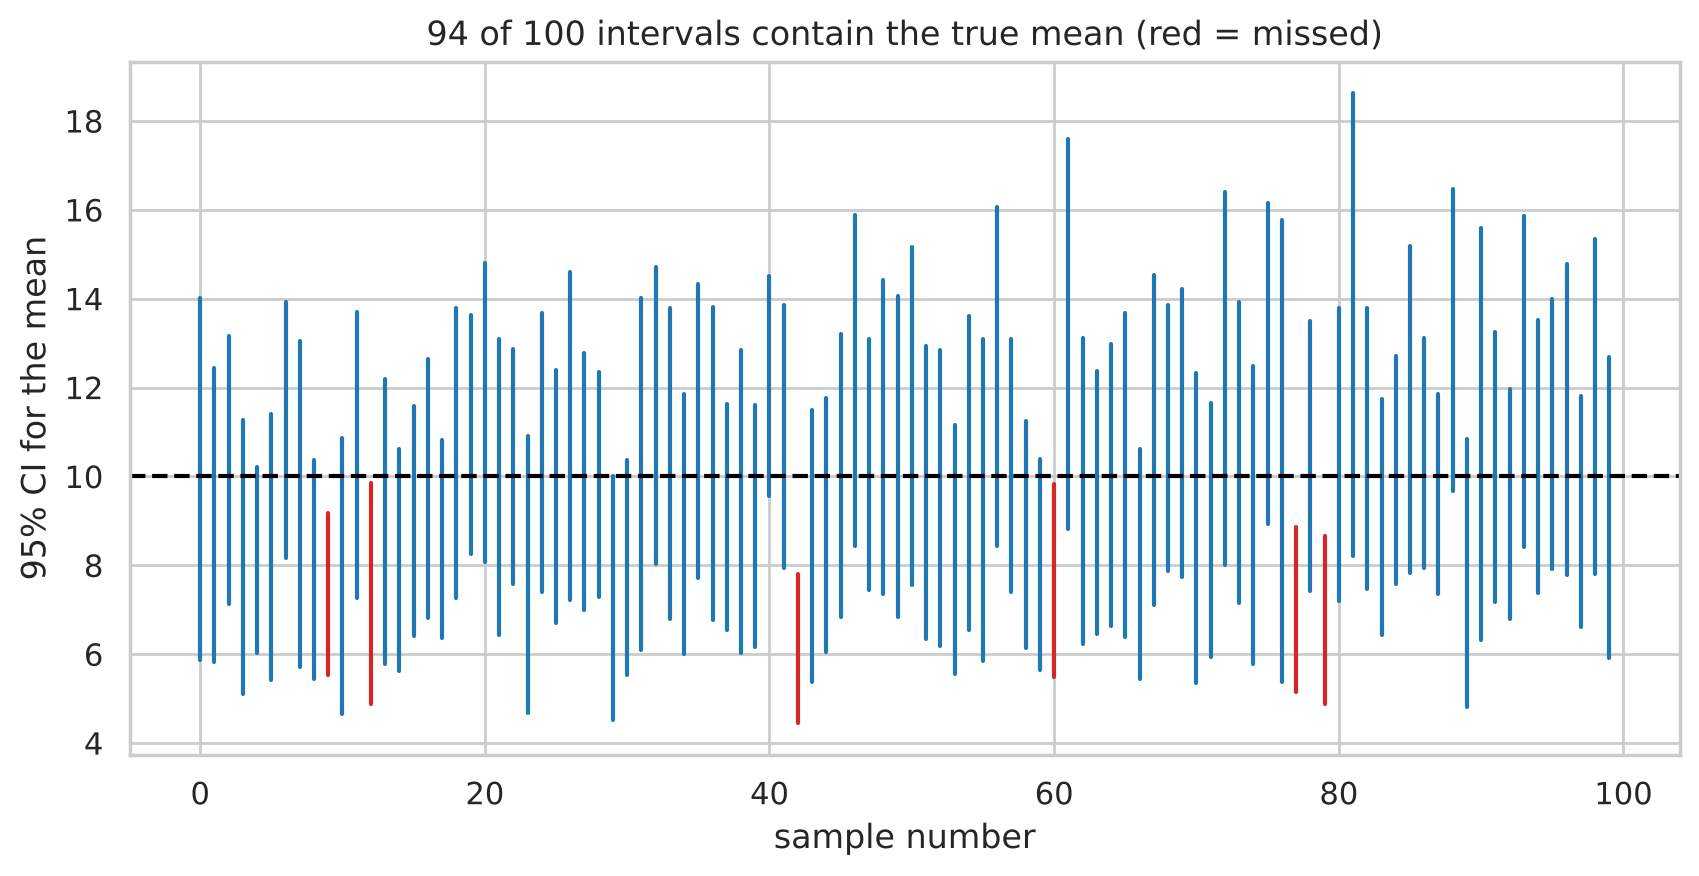

In [6]:
true_mu, n, reps = 10, 40, 100
fig, ax = plt.subplots(figsize=(10, 4.5))
misses = 0
for i in range(reps):
    sample = rng.choice(population, size=n)
    m, se = sample.mean(), sample.std(ddof=1) / np.sqrt(n)
    lo, hi = stats.t.interval(0.95, df=n - 1, loc=m, scale=se)
    hit = lo <= true_mu <= hi
    misses += not hit
    ax.plot([i, i], [lo, hi], color="tab:blue" if hit else "tab:red", linewidth=1.5)
ax.axhline(true_mu, color="black", linestyle="--")
ax.set_xlabel("sample number")
ax.set_ylabel("95% CI for the mean")
ax.set_title(f"{reps - misses} of {reps} intervals contain the true mean (red = missed)")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### بوت‌استرپ (Bootstrap): بازهٔ اطمینان برای هر آماره‌ای

فرمول بالا فقط برای میانگین است. برای میانه یا هر آمارهٔ دیگری می‌توانیم از **بوت‌استرپ** استفاده کنیم: از **خود نمونه** با جایگذاری بارها نمونه می‌گیریم و آماره را حساب می‌کنیم.

</div>

median tip % = 15.48, 95% bootstrap CI = [14.96, 16.11]


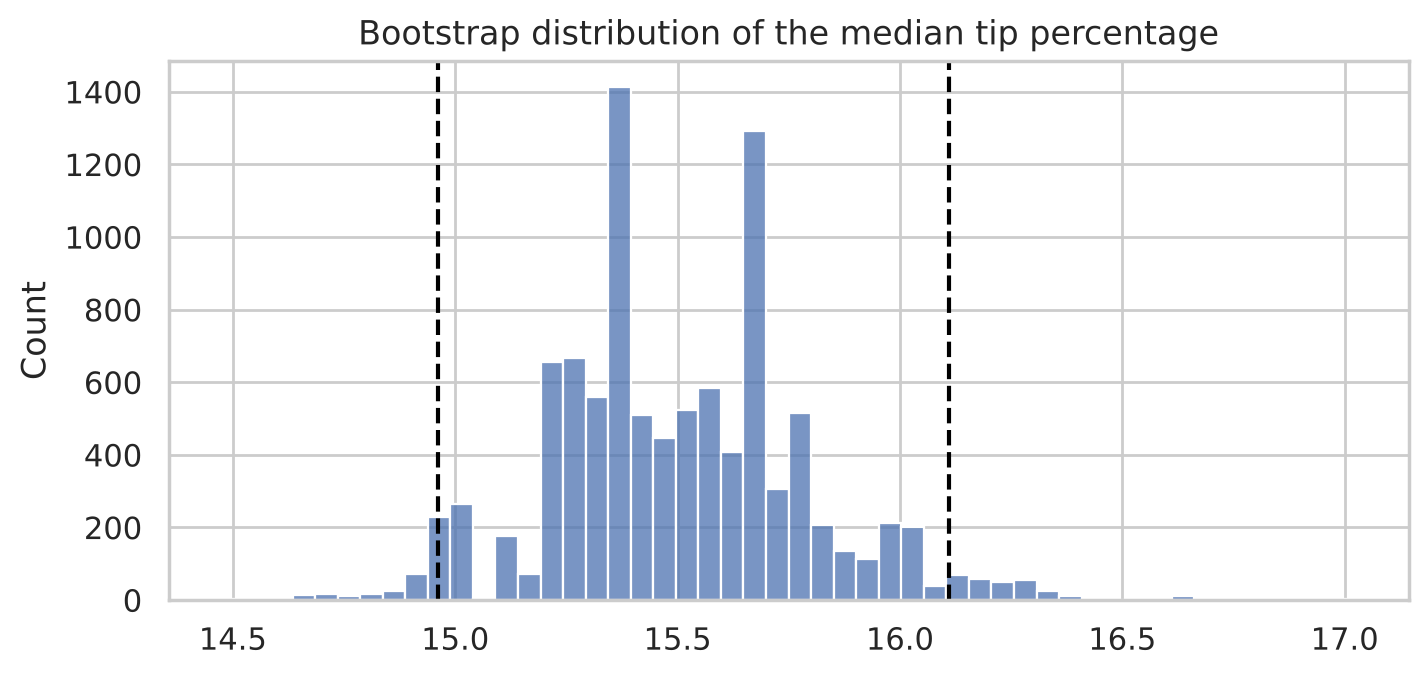

In [7]:
boot_medians = np.array([np.median(rng.choice(s.values, size=len(s), replace=True)) for _ in range(10_000)])
lo, hi = np.percentile(boot_medians, [2.5, 97.5])
print(f"median tip % = {s.median():.2f}, 95% bootstrap CI = [{lo:.2f}, {hi:.2f}]")

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(boot_medians, bins=50, ax=ax)
ax.axvline(lo, color="black", linestyle="--")
ax.axvline(hi, color="black", linestyle="--")
ax.set_title("Bootstrap distribution of the median tip percentage")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۴. آزمون فرض

ساختار هر آزمون فرض:

1. **فرض صفر** $H_0$: «هیچ اثری وجود ندارد» (مثلاً میانگین دو گروه برابر است).
2. **فرض مقابل** $H_1$: اثری وجود دارد.
3. یک **آمارهٔ آزمون** از داده حساب می‌کنیم.
4. **p-value**: اگر $H_0$ درست باشد، احتمال دیدن نتیجه‌ای به این اندازه یا شدیدتر چقدر است؟
5. اگر p-value از سطح معنی‌داری $\alpha$ (معمولاً ۰٫۰۵) کمتر باشد، $H_0$ را رد می‌کنیم.

| | $H_0$ درست است | $H_0$ غلط است |
|---|---|---|
| $H_0$ را رد می‌کنیم | **خطای نوع اول** (مثبت کاذب)، احتمال $\alpha$ | تصمیم درست (توان آزمون) |
| $H_0$ را رد نمی‌کنیم | تصمیم درست | **خطای نوع دوم** (منفی کاذب) |

> p-value **احتمال درست بودن** $H_0$ نیست. و «رد نکردن $H_0$» به معنای «اثبات نبودن اثر» نیست؛ شاید فقط دادهٔ کافی نداشته‌ایم.

### آزمون t دونمونه‌ای

**سؤال:** آیا سیگاری‌ها درصد انعام متفاوتی می‌دهند؟

</div>

In [8]:
smoker = tips.loc[tips["smoker"] == "Yes", "tip_pct"]
non_smoker = tips.loc[tips["smoker"] == "No", "tip_pct"]
print(f"smokers     : mean {smoker.mean():.2f}%  (n={len(smoker)})")
print(f"non-smokers : mean {non_smoker.mean():.2f}%  (n={len(non_smoker)})")

result = stats.ttest_ind(smoker, non_smoker, equal_var=False)    # Welch's t-test
print(f"t = {result.statistic:.3f}, p-value = {result.pvalue:.3f}")

smokers     : mean 16.32%  (n=93)
non-smokers : mean 15.93%  (n=151)
t = 0.411, p-value = 0.682


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

p-value حدود ۰٫۶۸ است: اگر واقعاً تفاوتی نباشد، دیدن اختلافی به این اندازه کاملاً عادی است. **شواهدی** برای تفاوت نداریم.

`equal_var=False` نسخهٔ **Welch** آزمون t است که برابری واریانس دو گروه را فرض نمی‌کند و به‌عنوان پیش‌فرض امن‌تر است.

### آزمون جایگشتی (Permutation Test): همان ایده، بدون فرمول

اگر برچسب «سیگاری» واقعاً بی‌اثر باشد، می‌توانیم برچسب‌ها را به‌طور تصادفی جابه‌جا کنیم و نتیجه نباید فرق کند. با هزاران بار جابه‌جایی، توزیع اختلاف میانگین **تحت فرض صفر** را می‌سازیم و می‌بینیم اختلاف واقعی کجای آن قرار دارد. این روش فرضی دربارهٔ شکل توزیع ندارد.

</div>

observed difference = 0.39, permutation p-value = 0.639


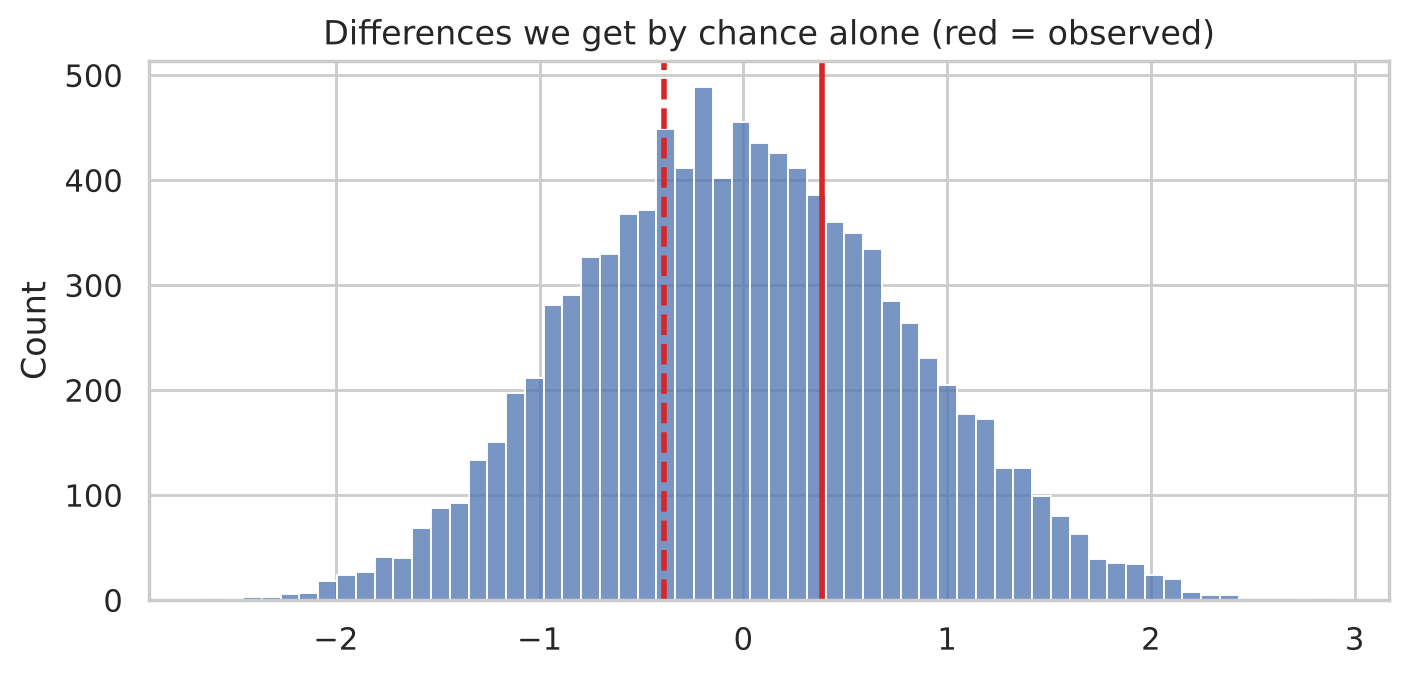

In [9]:
def permutation_test(a, b, n_perm=10_000):
    observed = a.mean() - b.mean()
    pooled = np.concatenate([a, b])
    diffs = np.empty(n_perm)
    for i in range(n_perm):
        rng.shuffle(pooled)
        diffs[i] = pooled[:len(a)].mean() - pooled[len(a):].mean()
    p = (np.abs(diffs) >= abs(observed)).mean()
    return observed, diffs, p

observed, diffs, p_perm = permutation_test(smoker.values, non_smoker.values)
print(f"observed difference = {observed:.2f}, permutation p-value = {p_perm:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(diffs, bins=60, ax=ax)
ax.axvline(observed, color="tab:red", linewidth=2)
ax.axvline(-observed, color="tab:red", linewidth=2, linestyle="--")
ax.set_title("Differences we get by chance alone (red = observed)")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آزمون کای‌دو: رابطهٔ دو متغیر دسته‌ای

در جلسهٔ قبل دیدیم نرخ زنده ماندن زنان در تایتانیک خیلی بیشتر بود. آیا این اختلاف می‌تواند تصادفی باشد؟ آزمون **کای‌دو استقلال** جدول توافقی مشاهده‌شده را با جدولی که در صورت استقلال انتظار داشتیم، مقایسه می‌کند.

</div>

In [10]:
titanic = pd.read_csv(DATA_URL + "titanic.csv")
table = pd.crosstab(titanic["sex"], titanic["survived"])
chi2, p, dof, expected = stats.chi2_contingency(table)
print("observed:\n", table, "\n")
print("expected if independent:\n", pd.DataFrame(expected, index=table.index, columns=table.columns).round(1), "\n")
print(f"chi2 = {chi2:.1f}, dof = {dof}, p-value = {p:.1e}")

observed:
 survived    0    1
sex               
female     81  233
male      468  109 

expected if independent:
 survived      0      1
sex                   
female    193.5  120.5
male      355.5  221.5 

chi2 = 260.7, dof = 1, p-value = 1.2e-58


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

p-value از مرتبهٔ $10^{-58}$ است؛ یعنی عملاً غیرممکن است چنین اختلافی تصادفی باشد.

## ۵. آزمون A/B

یک فروشگاه اینترنتی می‌خواهد بداند دکمهٔ خرید جدید (نسخهٔ B) نرخ تبدیل را بیشتر می‌کند یا نه. کاربران به‌طور **تصادفی** به دو گروه تقسیم شده‌اند. تقسیم تصادفی مهم‌ترین بخش آزمایش است: تضمین می‌کند که تنها تفاوت سیستماتیک دو گروه، خود دکمه است و بنابراین می‌توانیم دربارهٔ **علیت** حرف بزنیم.

</div>

In [11]:
ab = pd.DataFrame({
    "group": np.repeat(["A", "B"], 4000),
    "converted": np.concatenate([rng.random(4000) < 0.100, rng.random(4000) < 0.118]).astype(int),
})
summary = ab.groupby("group")["converted"].agg(users="count", conversions="sum", rate="mean")
summary

,users,conversions,rate
group,,,
A,4000,369,0.09225
B,4000,461,0.11525


In [12]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

conv = summary["conversions"].values
users = summary["users"].values
z, p = proportions_ztest(conv[::-1], users[::-1])     # order: B, A
lo, hi = confint_proportions_2indep(conv[1], users[1], conv[0], users[0])
lift = summary.loc["B", "rate"] - summary.loc["A", "rate"]

print(f"difference B - A = {lift * 100:.2f} percentage points")
print(f"95% CI           = [{lo * 100:.2f}, {hi * 100:.2f}] percentage points")
print(f"z = {z:.2f}, p-value = {p:.4f}")

difference B - A = 2.30 percentage points
95% CI           = [0.96, 3.64] percentage points
z = 3.37, p-value = 0.0007


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

گزارش کامل یک آزمون A/B فقط «معنی‌دار بود» نیست؛ باید بگوییم **چقدر** بهبود داشتیم و با چه عدم قطعیتی. بازهٔ اطمینان اختلاف، پاسخ هر دو سؤال است: اگر کل بازه بالای صفر باشد، اثر مثبت است؛ عرض بازه هم نشان می‌دهد تخمین ما چقدر دقیق است.

### اندازهٔ نمونه چقدر باید باشد؟

اثرهای کوچک به نمونه‌های بزرگ نیاز دارند. پیش از شروع آزمایش باید حساب کنیم برای دیدن اثر مورد نظر، چند کاربر لازم است (**تحلیل توان**):

</div>

In [13]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

for target in [0.105, 0.110, 0.120, 0.150]:
    effect = proportion_effectsize(target, 0.10)
    n_needed = NormalIndPower().solve_power(effect_size=effect, alpha=0.05, power=0.8)
    print(f"10% -> {target:.1%}: about {int(np.ceil(n_needed)):>6,} users per group")

10% -> 10.5%: about 57,756 users per group
10% -> 11.0%: about 14,745 users per group
10% -> 12.0%: about  3,835 users per group
10% -> 15.0%: about    681 users per group


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

برای دیدن بهبود ۱۰٪ به ۱۰٫۵٪، نزدیک به ۵۸ هزار کاربر در **هر** گروه لازم است؛ اما برای دیدن جهش ۱۰٪ به ۱۵٪، کمتر از ۷۰۰ کاربر کافی است.

## ۶. اندازهٔ اثر: معنی‌داری آماری با اهمیت عملی یکی نیست

با نمونهٔ خیلی بزرگ، حتی اختلاف‌های **ناچیز** هم معنی‌دار می‌شوند. به همین دلیل همیشه کنار p-value، **اندازهٔ اثر** را هم گزارش کنید. یکی از رایج‌ترین‌ها **d کوهن** است: اختلاف میانگین‌ها بر حسب انحراف معیار.

$$d = \frac{\bar{x}_1 - \bar{x}_2}{s_{pooled}}$$

قاعدهٔ سرانگشتی: ۰٫۲ کوچک، ۰٫۵ متوسط، ۰٫۸ بزرگ.

</div>

In [14]:
def cohens_d(a, b):
    na, nb = len(a), len(b)
    pooled = np.sqrt(((na - 1) * np.var(a, ddof=1) + (nb - 1) * np.var(b, ddof=1)) / (na + nb - 2))
    return (np.mean(a) - np.mean(b)) / pooled

for n in [50, 500, 50_000]:
    a = rng.normal(100.0, 15, n)
    b = rng.normal(100.5, 15, n)      # a tiny true difference
    p = stats.ttest_ind(a, b).pvalue
    print(f"n = {n:>6,}: p-value = {p:.4f}, Cohen's d = {abs(cohens_d(a, b)):.3f}")

n =     50: p-value = 0.9375, Cohen's d = 0.016
n =    500: p-value = 0.5279, Cohen's d = 0.040
n = 50,000: p-value = 0.0000, Cohen's d = 0.041


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۷. همبستگی

**ضریب همبستگی پیرسون** ($r$) شدت رابطهٔ **خطی** بین دو متغیر را بین ۱- و ۱+ می‌سنجد. **اسپیرمن** فقط رابطهٔ **یکنوا** (صعودی یا نزولی) را می‌سنجد و به دادهٔ پرت مقاوم‌تر است.

</div>

In [15]:
r, p = stats.pearsonr(tips["total_bill"], tips["tip"])
rho, _ = stats.spearmanr(tips["total_bill"], tips["tip"])
print(f"total_bill vs tip     : Pearson r = {r:.2f} (p = {p:.1e}), Spearman rho = {rho:.2f}")
r2, _ = stats.pearsonr(tips["total_bill"], tips["tip_pct"])
print(f"total_bill vs tip_pct : Pearson r = {r2:.2f}")

total_bill vs tip     : Pearson r = 0.68 (p = 6.7e-34), Spearman rho = 0.68
total_bill vs tip_pct : Pearson r = -0.34


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

انعام با مبلغ صورت‌حساب همبستگی مثبت قوی دارد (طبیعی است)، اما **درصد** انعام با مبلغ همبستگی منفی دارد: مشتری‌ها در صورت‌حساب‌های بزرگ درصد کمتری انعام می‌دهند.

### همبستگی، علیت نیست

همبستگی صفر هم به معنای «بی‌رابطه» نیست. چهار مجموعه‌دادهٔ **آنسکوم** میانگین، واریانس و همبستگی تقریباً **یکسان** دارند، اما کاملاً متفاوت‌اند:

</div>

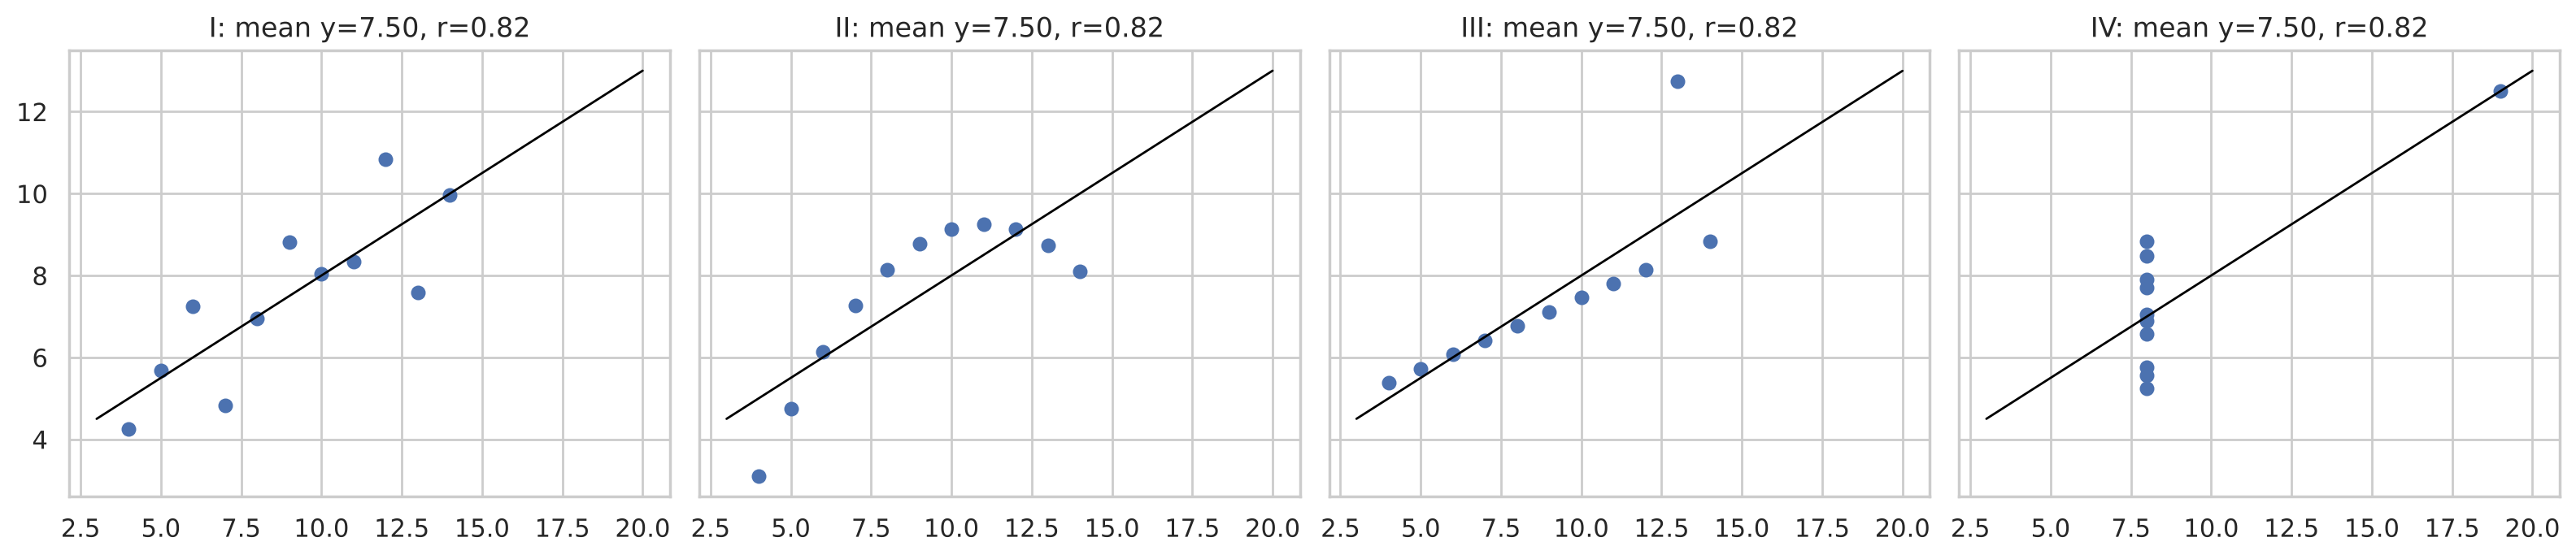

In [16]:
anscombe = {
    "I":   ([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5], [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "II":  ([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5], [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "III": ([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5], [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "IV":  ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, (name, (x, y)) in zip(axes, anscombe.items()):
    x, y = np.array(x), np.array(y)
    ax.scatter(x, y, s=30)
    slope, intercept = np.polyfit(x, y, 1)
    xs = np.array([3, 20])
    ax.plot(xs, slope * xs + intercept, color="black", linewidth=1)
    ax.set_title(f"{name}: mean y={y.mean():.2f}, r={np.corrcoef(x, y)[0, 1]:.2f}")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

درس: **همیشه داده را رسم کنید.** و حتی همبستگی قوی هم دلیلی بر علیت نیست:

- **متغیر مخدوش‌کننده:** فروش بستنی و غرق‌شدگی همبستگی دارند، چون هر دو در تابستان زیاد می‌شوند.
- **علیت معکوس:** شهرهای با پلیس بیشتر جرم بیشتری دارند؛ چون پلیس به جاهای پرجرم فرستاده می‌شود.
- **تصادف:** با تعداد کافی متغیر، همبستگی‌های بی‌معنی همیشه پیدا می‌شوند.

تنها راه مطمئن برای نتیجه‌گیری علّی، **آزمایش تصادفی‌شده** است (مثل آزمون A/B).

## ۸. خطر آزمون‌های چندگانه

اگر $\alpha = 0.05$ باشد، یعنی وقتی هیچ اثری وجود ندارد، ۵٪ مواقع به اشتباه «اثر» پیدا می‌کنیم. حالا اگر ۲۰ آزمون انجام دهیم چه؟

دادهٔ فروشگاه اینترنتی این دوره ساختگی است و **ما می‌دانیم** که امتیاز مشتری‌ها کاملاً تصادفی و مستقل از روش پرداخت و شهر تولید شده است. پس هر «اختلاف معنی‌داری» که پیدا کنیم، مثبت کاذب است. بیایید همهٔ جفت‌شهرها و جفت‌روش‌های پرداخت را آزمون کنیم:

</div>

In [17]:
from itertools import combinations

orders = pd.read_csv(DATA_URL + "orders_clean.csv")
rated = orders.dropna(subset=["rating"])

results = []
for col in ["city", "payment_method"]:
    groups = {k: g["rating"].values for k, g in rated.groupby(col) if len(g) >= 30}
    for a, b in combinations(groups, 2):
        p = stats.ttest_ind(groups[a], groups[b], equal_var=False).pvalue
        results.append({"comparison": f"{col}: {a} vs {b}", "p_value": p})

results = pd.DataFrame(results).sort_values("p_value")
print(f"{len(results)} tests, {(results['p_value'] < 0.05).sum()} 'significant' at 0.05")
results.head(5).round(4)

31 tests, 2 'significant' at 0.05


,comparison,p_value
29,payment_method: card vs wallet,0.0114
30,payment_method: cash_on_delivery vs wallet,0.0447
22,city: Sari vs Shiraz,0.0838
25,city: Shiraz vs Tabriz,0.0850
26,city: Shiraz vs Tehran,0.1220


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

از ۳۱ آزمون، دو نتیجهٔ «معنی‌دار» پیدا کردیم، در حالی که می‌دانیم هیچ اثر واقعی وجود ندارد! (با ۳۱ آزمون و $\alpha=0.05$، به‌طور میانگین حدود ۱٫۵ مثبت کاذب انتظار داریم.) اگر فقط همین نتایج را گزارش کنیم (مثلاً «مشتری‌هایی که با کارت پرداخت می‌کنند رضایت بیشتری دارند»)، یک یافتهٔ جعلی ساخته‌ایم. به این کار **p-hacking** می‌گویند.

راه‌حل سادهٔ **بن‌فرونی**: سطح معنی‌داری را بر تعداد آزمون‌ها تقسیم کنید. روش‌های دقیق‌تری مثل **Holm** و **Benjamini-Hochberg** هم وجود دارند:

</div>

In [18]:
from statsmodels.stats.multitest import multipletests

for method in ["bonferroni", "holm", "fdr_bh"]:
    reject, *_ = multipletests(results["p_value"], alpha=0.05, method=method)
    print(f"{method:10s}: {reject.sum()} significant after correction")

bonferroni: 0 significant after correction
holm      : 0 significant after correction
fdr_bh    : 0 significant after correction


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## جمع‌بندی

- برای دادهٔ چوله یا دارای پرت، میانه و IQR را گزارش کنید.
- قضیهٔ حد مرکزی: میانگین نمونه‌ها تقریباً نرمال است و خطای استاندارد با $\sqrt{n}$ کم می‌شود.
- تخمین را همیشه با **بازهٔ اطمینان** گزارش کنید؛ بوت‌استرپ برای هر آماره‌ای کار می‌کند.
- p-value احتمال درستی $H_0$ نیست؛ همراهش اندازهٔ اثر را گزارش کنید.
- برای نتیجهٔ علّی، آزمایش تصادفی‌شده لازم است.
- آزمون‌های زیاد، مثبت کاذب زیاد می‌سازند؛ اصلاح کنید و از قبل مشخص کنید چه چیزی را آزمون می‌کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. بازهٔ اطمینان ۹۵٪ برای میانگین `total_bill` را با فرمول و با بوت‌استرپ حساب کنید و مقایسه کنید.

۲. آیا درصد انعام در شام و ناهار متفاوت است؟ آزمون t و آزمون جایگشتی را انجام دهید و نتیجه را در یک جمله بنویسید.

۳. با آزمون کای‌دو بررسی کنید که آیا زنده ماندن در تایتانیک به کلاس سفر (`pclass`) وابسته است.

۴. آزمون A/B بالا را با ۵۰۰ کاربر در هر گروه (به‌جای ۴۰۰۰) دوباره شبیه‌سازی کنید. چند بار از ۱۰۰ بار اجرا، اثر واقعی را تشخیص می‌دهید؟ (این عدد، **توان** آزمون است.)

۵. شبیه‌سازی کنید: اگر ۲۰ آزمون مستقل روی دادهٔ کاملاً تصادفی انجام دهیم، احتمال اینکه **حداقل یکی** معنی‌دار شود چقدر است؟ با مقدار نظری $1 - 0.95^{20}$ مقایسه کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** بازهٔ اطمینان ۹۵٪ برای میانگین `total_bill` را با فرمول و با بوت‌استرپ حساب کنید و مقایسه کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** آیا درصد انعام در شام و ناهار متفاوت است؟ آزمون t و آزمون جایگشتی را انجام دهید و نتیجه را در یک جمله بنویسید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** با آزمون کای‌دو بررسی کنید که آیا زنده ماندن در تایتانیک به کلاس سفر (`pclass`) وابسته است.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** آزمون A/B بالا را با ۵۰۰ کاربر در هر گروه (به‌جای ۴۰۰۰) دوباره شبیه‌سازی کنید. چند بار از ۱۰۰ بار اجرا، اثر واقعی را تشخیص می‌دهید؟ (این عدد، **توان** آزمون است.)

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۵.** شبیه‌سازی کنید: اگر ۲۰ آزمون مستقل روی دادهٔ کاملاً تصادفی انجام دهیم، احتمال اینکه **حداقل یکی** معنی‌دار شود چقدر است؟ با مقدار نظری $1 - 0.95^{20}$ مقایسه کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید
